# Phase 3: Features + classification (charvi, patient 1)

I classify the dark spots inside my predicted liver as tumour (at least 50% tumour) or healthy (no tumour) with k-NN.

## Step 0: Setup

Imports, folders and the loader.

In [1]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import skew, kurtosis, mannwhitneyu
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

NAME = "charvi"
SLICES = "../data/slices/" + NAME                   # raw CT (HU) + ground-truth masks
ENH = "../phase1/outputs_charvi/enhanced"           # Phase 1 output
LIVER = "../phase2/outputs_charvi/regiongrow"       # Phase 2 output (best method)
OUT = "outputs_charvi"
FIGS = "../report/figures/charvi"
os.makedirs(OUT, exist_ok=True)

# list the slice ids (e.g. p1_s60) from the enhanced images
slice_ids = []
for f in glob.glob(ENH + "/*_enh.png"):
    slice_ids.append(os.path.basename(f).replace("_enh.png", ""))
slice_ids = sorted(slice_ids)
print(len(slice_ids), "slices")


def load(sid):
    ct = np.load(SLICES + "/" + sid + "_ct.npy")                              # raw HU (for first-order stats)
    enhanced_img = cv2.imread(ENH + "/" + sid + "_enh.png", 0)                # enhanced 0-255 (for texture)
    liver_mask = cv2.imread(LIVER + "/" + sid + "_liver_pred.png", 0) > 0     # predicted liver
    tumour_mask = cv2.imread(SLICES + "/" + sid + "_tumour.png", 0) > 0       # ground-truth tumour
    return ct, enhanced_img, liver_mask, tumour_mask

18 slices


## Step 1: Feature functions

Shape, GLCM at 4 angles and first-order HU statistics.

In [2]:
# ---- simple regional descriptors (area, perimeter, compactness) ----
def shape_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    area = r.area
    perim = max(r.perimeter, 1e-6)
    feats = {}
    feats["area"] = area
    feats["perimeter_area_ratio"] = perim / area
    feats["circularity"] = 4 * np.pi * area / perim ** 2      # 1 = perfect circle
    feats["compactness"] = perim ** 2 / area   # perimeter^2 / area
    feats["eccentricity"] = r.eccentricity                    # 0 = circle, 1 = line
    feats["solidity"] = r.solidity                            # area / convex hull area
    return feats

In [3]:
# ---- GLCM (grey level co-occurrence matrix), 2nd-order texture ----
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]           # 0, 45, 90, 135 degrees
ANGLE_NAMES = ["0", "45", "90", "135"]


def glcm_features(enhanced_img, mask, levels=32, per_angle=False):
    # GLCM texture inside the region only (pixels outside the region are ignored)
    r = regionprops(mask.astype(np.uint8))[0]
    r0, c0, r1, c1 = r.bbox
    patch = enhanced_img[r0:r1, c0:c1].astype(int)
    m = mask[r0:r1, c0:c1]

    # quantise to 1..levels inside the region, 0 outside
    q = np.where(m, 1 + patch * (levels - 1) // 255, 0).astype(np.uint8)
    P = graycomatrix(q, distances=[1], angles=ANGLES, levels=levels + 1)
    P = P[1:, 1:, :, :].astype(float)                                      # drop pairs touching "outside"
    P = P / np.maximum(P.sum(axis=(0, 1), keepdims=True), 1e-12)           # normalise: counts -> probabilities

    feats = {}
    for prop in ["energy", "contrast", "homogeneity", "correlation"]:
        vals = np.nan_to_num(graycoprops(P, prop)[0])                     # one value per angle
        if per_angle:
            for i in range(4):
                feats[f"glcm_{prop}_{ANGLE_NAMES[i]}"] = vals[i]
        else:
            feats[f"glcm_{prop}"] = vals.mean()

    # entropy of the GLCM at each angle
    ent = []
    for k in range(4):
        p_k = P[:, :, 0, k]
        nonzero = p_k[p_k > 0]
        ent.append(-(nonzero * np.log2(nonzero)).sum())
    if per_angle:
        for i in range(4):
            feats[f"glcm_entropy_{ANGLE_NAMES[i]}"] = ent[i]
    else:
        feats["glcm_entropy"] = np.mean(ent)
    return feats


def glcm_angle_table(enhanced_img, mask):
    # one column per angle, one row per GLCM property
    t = pd.Series(glcm_features(enhanced_img, mask, per_angle=True))
    table = {}
    for a in ANGLE_NAMES:
        keys = []
        for k in t.index:
            if k.endswith("_" + a):
                keys.append(k)
        table[a] = t[keys].values
    table = pd.DataFrame(table, index=["energy", "contrast", "homogeneity", "correlation", "entropy"])
    return table.round(3)

In [4]:
# ---- histogram based 1st-order statistics (statistical moments) of the HU values ----
def first_order_features(ct, mask):
    hu = ct[mask].astype(float)
    feats = {}
    feats["mean_HU"] = hu.mean()
    feats["variance_HU"] = hu.var()
    if hu.std() > 0:
        feats["skewness"] = skew(hu)
        feats["kurtosis"] = kurtosis(hu)
    else:
        feats["skewness"] = 0.0
        feats["kurtosis"] = 0.0
    return feats

## Step 2: Candidate spots

Spots darker than the liver median - 1.5 x std, away from the liver edge.

In [5]:
# ---- candidate regions: dark spots inside the predicted liver ----
MIN_AREA = 10
DARK_K = 1.5


def candidate_spots(enhanced_img, liver_mask):
    # dark spots inside the liver: darker than (median - 1.5 x std) of the liver
    # erode with a 9x9 structuring element to stay away from the liver edge
    square_9 = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    inner = cv2.erode(liver_mask.astype(np.uint8), square_9) > 0
    if not inner.any():
        return np.zeros_like(liver_mask)
    # threshold = median - 1.5 x std of the liver pixels
    threshold = np.median(enhanced_img[inner]) - DARK_K * enhanced_img[inner].std()
    dark = (enhanced_img < threshold) & inner
    # opening with a 3x3 structuring element removes single-pixel specks
    square_3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    return cv2.morphologyEx(dark.astype(np.uint8), cv2.MORPH_OPEN, square_3) > 0

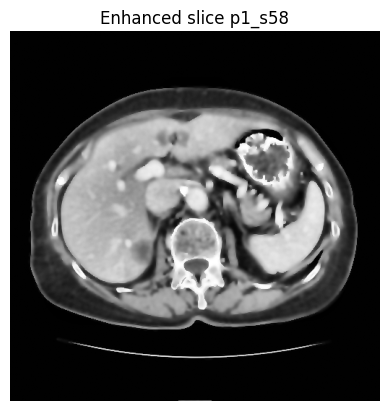

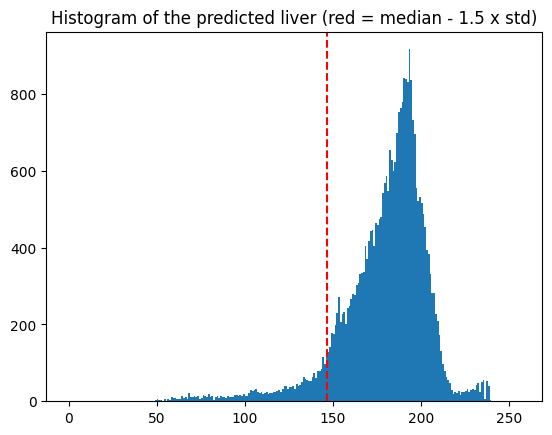

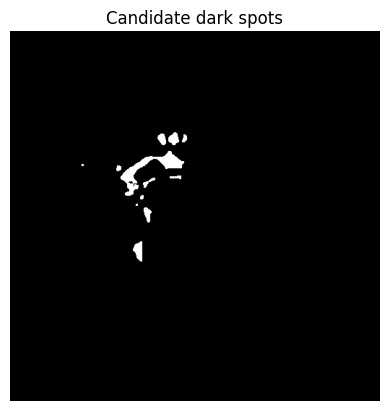

In [6]:
# one example slice: show it -> histogram -> threshold -> binary mask
example_sid = slice_ids[0]
biggest = -1
for sid in slice_ids:
    ct, enhanced_img, liver_mask, tumour_mask = load(sid)
    if tumour_mask.sum() > biggest:
        biggest = tumour_mask.sum()
        example_sid = sid
ct, enhanced_img, liver_mask, tumour_mask = load(example_sid)

plt.figure()
plt.imshow(enhanced_img, cmap='gray')
plt.title('Enhanced slice ' + example_sid)
plt.axis('off')
plt.show()

# look at the histogram of the liver pixels: tumours are on the dark side
liver_pixels = enhanced_img[liver_mask]
liver_threshold = np.median(liver_pixels) - DARK_K * liver_pixels.std()
plt.figure()
plt.hist(liver_pixels.ravel(), bins=256, range=(0, 256))
plt.axvline(liver_threshold, color='red', linestyle='--')
plt.title('Histogram of the predicted liver (red = median - 1.5 x std)')
plt.show()

# binary image of the candidate spots (white = could be tumour)
plt.figure()
plt.imshow(candidate_spots(enhanced_img, liver_mask), cmap='gray')
plt.title('Candidate dark spots')
plt.axis('off')
plt.show()

In [7]:
# tumour if >= 50% inside the true tumour, healthy if no tumour pixels, else skip
rois = []                      # (slice id, region mask, label)  label: 1 = tumour, 0 = healthy
skipped = 0
for sid in slice_ids:
    ct, enhanced_img, liver_mask, tumour_mask = load(sid)
    spots = label(candidate_spots(enhanced_img, liver_mask))   # connected components
    for r in regionprops(spots):
        if r.area < MIN_AREA:
            continue
        m = np.zeros(tumour_mask.shape, bool)
        m[tuple(r.coords.T)] = True
        inside = tumour_mask[m].mean()                     # share of the spot that is real tumour
        if inside >= 0.5:
            rois.append((sid, m, 1))
        elif inside == 0:
            rois.append((sid, m, 0))
        else:
            skipped += 1

roi_labels = []
tumour_slice_set = set()
for sid, m, roi_label in rois:
    roi_labels.append(roi_label)
    if roi_label == 1:
        tumour_slice_set.add(sid)
roi_labels = np.array(roi_labels)
tumour_slices = len(tumour_slice_set)
print(len(rois), "regions:", (roi_labels == 1).sum(), "tumour (on", tumour_slices, "slices),", (roi_labels == 0).sum(), "healthy |",
      skipped, "mixed spots skipped")

146 regions: 26 tumour (on 15 slices), 120 healthy | 7 mixed spots skipped


In [8]:
# GLCM table at the 4 angles for the largest tumour region (for the report)
largest = -1
for roi in rois:
    if roi[2] == 1 and roi[1].sum() > largest:
        largest = roi[1].sum()
        sid = roi[0]
        m = roi[1]
ct, enhanced_img, liver_mask, tumour_mask = load(sid)
glcm_example = glcm_angle_table(enhanced_img, m)

print(f"\nGLCM at 4 angles, largest tumour region ({sid}):")
print(glcm_example)
glcm_example.to_csv(FIGS + "/" + NAME + "_glcm_table.csv")


GLCM at 4 angles, largest tumour region (p1_s62):
                 0     45     90    135
energy       0.288  0.264  0.287  0.260
contrast     0.373  0.556  0.382  0.558
homogeneity  0.813  0.754  0.811  0.730
correlation  0.937  0.903  0.935  0.903
entropy      3.901  4.142  3.913  4.095


## Step 3: My own features, LBP

The histogram of uniform LBP codes inside each region.

In [9]:
# ---- LBP: charvi's own feature set ----
LBP_P = 8           # 8 neighbours on a circle of radius 1
LBP_R = 1


def lbp_features(enhanced_img, mask):
    # LBP code per pixel (8 neighbours), normalised histogram inside the region
    codes = local_binary_pattern(enhanced_img, LBP_P, LBP_R, method="uniform")
    hist = np.bincount(codes[mask].astype(int), minlength=LBP_P + 2) / mask.sum()
    feats = {}
    for i in range(len(hist)):
        feats[f"lbp_{i}"] = hist[i]
    return feats

In [10]:
# measure every feature for every region -> one row per region
cache = {}
feature_rows = []
for sid, m, roi_label in rois:
    if sid not in cache:
        cache[sid] = load(sid)
    ct, enhanced_img, liver_mask, tumour_mask = cache[sid]
    row = {}
    row["slice"] = sid
    row["label"] = roi_label
    for feats in [shape_features(m), glcm_features(enhanced_img, m), first_order_features(ct, m), lbp_features(enhanced_img, m)]:
        for key in feats:
            row[key] = feats[key]
    feature_rows.append(row)

features = pd.DataFrame(feature_rows)
features.to_csv(OUT + "/phase3_features.csv", index=False)

# mean of every feature, healthy vs tumour
class_means = features.groupby("label").mean(numeric_only=True)
class_means = class_means.T.round(3)
class_means = class_means.rename(columns={0: "healthy", 1: "tumour"})
print(class_means)

label                 healthy   tumour
area                  125.692  215.231
perimeter_area_ratio    0.534    0.326
circularity             0.914    0.905
compactness            17.459   14.261
eccentricity            0.775    0.636
solidity                0.897    0.937
glcm_energy             0.612    0.451
glcm_contrast           0.517    0.409
glcm_homogeneity        0.831    0.808
glcm_correlation        0.652    0.684
glcm_entropy            2.007    2.784
mean_HU                85.450   75.616
variance_HU           388.903  216.297
skewness               -0.217    0.139
kurtosis               -0.258   -0.231
lbp_0                   0.001    0.000
lbp_1                   0.003    0.001
lbp_2                   0.004    0.002
lbp_3                   0.046    0.033
lbp_4                   0.278    0.409
lbp_5                   0.318    0.390
lbp_6                   0.117    0.096
lbp_7                   0.075    0.027
lbp_8                   0.136    0.035
lbp_9                   0

## Step 4: Grouped train / test split

Neighbouring slices stay on the same side of the 70/30 split.

In [11]:
X = features.drop(columns=["slice", "label"]).values
y = features["label"].values

# ---- grouped split: all regions of a slice stay on one side ----
# neighbouring slices look alike, so they are grouped too
# blocks of 3 (or 2) slices, if >= 5 training groups are left
slice_no = features["slice"].str.extract(r"_s(\d+)")[0].astype(int)
position_of = {}
i = 0
for s in sorted(slice_no.unique()):
    position_of[s] = i
    i = i + 1
position = slice_no.map(position_of).values      # 0, 1, 2, ... along the scan


def grouped_split(groups):
    # 70/30 split by group: try 50 seeds, keep the test part closest to 30% of the regions
    best_split = None
    best_gap = 1.0
    for seed in range(50):
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
        tr, te = next(splitter.split(X, y, groups))
        gap = abs(len(te) / len(y) - 0.3)
        if len(np.unique(groups[tr])) >= 5 and len(np.unique(y[te])) == 2 and gap < best_gap:
            best_split = (tr, te)
            best_gap = gap
    return best_split


for BLOCK in (3, 2, 1):
    groups = position // BLOCK
    split = grouped_split(groups)
    if split is not None:
        break
idx_train, idx_test = split
X_train = X[idx_train]
X_test = X[idx_test]
y_train = y[idx_train]
y_test = y[idx_test]
print(f"block = {BLOCK} slice(s) per group | train: {len(np.unique(groups[idx_train]))} groups, {len(idx_train)} regions"
      f" | test: {len(np.unique(groups[idx_test]))} groups, {len(idx_test)} regions"
      f" ({len(idx_test) / len(y):.0%} of all regions)")

block = 2 slice(s) per group | train: 6 groups, 102 regions | test: 3 groups, 44 regions (30% of all regions)


## Step 5: k-NN classifier

Grouped 5-fold CV picks k from 1, 3, 5, 7, 9.

In [12]:
# ---- classifier: k-nearest neighbours ----
# k-NN: majority label of the k closest regions
# grouped 5-fold CV on the 70% train part picks k
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
knn_pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier())
search = GridSearchCV(knn_pipeline, {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9]}, cv=cv5, scoring="f1")
search.fit(X_train, y_train, groups=groups[idx_train])
best = search.best_params_["kneighborsclassifier__n_neighbors"]
model = search.best_estimator_                     # already refitted on the whole 70% train part
y_pred = model.predict(X_test)

cv = cross_validate(model, X_train, y_train, groups=groups[idx_train], cv=cv5, scoring=["accuracy", "f1"])
print(f"tuned k = {best}  (tried [1, 3, 5, 7, 9])")
print(f"5-fold grouped CV on train: accuracy {cv['test_accuracy'].mean():.3f} +/- {cv['test_accuracy'].std():.3f}"
      f"  folds: {np.round(cv['test_accuracy'], 3)}")
print(f"                            F1       {cv['test_f1'].mean():.3f} +/- {cv['test_f1'].std():.3f}"
      f"  folds: {np.round(cv['test_f1'], 3)}")

cv_summary = {}
cv_summary["tuned k"] = best
cv_summary["group block (slices)"] = BLOCK
cv_summary["CV accuracy mean"] = cv["test_accuracy"].mean()
cv_summary["CV accuracy std"] = cv["test_accuracy"].std()
cv_summary["CV F1 mean"] = cv["test_f1"].mean()
cv_summary["CV F1 std"] = cv["test_f1"].std()

tuned k = 5  (tried [1, 3, 5, 7, 9])
5-fold grouped CV on train: accuracy 0.921 +/- 0.024  folds: [0.913 0.889 0.95  0.947 0.903]
                            F1       0.743 +/- 0.143  folds: [0.5   0.667 0.857 0.889 0.8  ]


## Step 6: Test results

Accuracy, sensitivity, specificity, F1, bootstrap CIs and the confusion matrix.

In [13]:
# ---- test set: accuracy, sensitivity (recall), specificity, F1 ----
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
metrics = {}
metrics["accuracy"] = accuracy_score(y_test, y_pred)
if tp + fn:
    metrics["sensitivity (recall)"] = tp / (tp + fn)     # tumours correctly found
else:
    metrics["sensitivity (recall)"] = 0
if tn + fp:
    metrics["specificity"] = tn / (tn + fp)              # healthy correctly cleared
else:
    metrics["specificity"] = 0
metrics["F1"] = f1_score(y_test, y_pred, zero_division=0)

print(f"Test set: {len(y_test)} regions ({(y_test == 1).sum()} tumour, {(y_test == 0).sum()} healthy)")
for k in metrics:
    print(f"  {k:22s} {metrics[k]:.3f}")

Test set: 44 regions (8 tumour, 36 healthy)
  accuracy               0.886
  sensitivity (recall)   0.500
  specificity            0.972
  F1                     0.615


In [14]:
# ---- 95% confidence intervals: bootstrap over the test GROUPS (slices), 2000 resamples ----
def scores(t, p):
    tn, fp, fn, tp = confusion_matrix(t, p, labels=[0, 1]).ravel()
    if tp + fn:
        sensitivity = tp / (tp + fn)
    else:
        sensitivity = np.nan
    if tn + fp:
        specificity = tn / (tn + fp)
    else:
        specificity = np.nan
    return [accuracy_score(t, p), sensitivity, specificity, f1_score(t, p, zero_division=0)]


boot_rng = np.random.default_rng(0)
test_groups = groups[idx_test]
unique_test_groups = np.unique(test_groups)
boot = []
for _ in range(2000):
    chosen_groups = boot_rng.choice(unique_test_groups, len(unique_test_groups))
    parts = []
    for g in chosen_groups:
        parts.append(np.where(test_groups == g)[0])
    pick = np.concatenate(parts)
    boot.append(scores(y_test[pick], y_pred[pick]))
lo = np.nanpercentile(boot, 2.5, axis=0)
hi = np.nanpercentile(boot, 97.5, axis=0)

ci = {}
print("95% bootstrap CI (test groups resampled):")
metric_names = list(metrics)
for i in range(len(metric_names)):
    k = metric_names[i]
    ci[f"{k} CI low"] = lo[i]
    ci[f"{k} CI high"] = hi[i]
    print(f"  {k:22s} [{lo[i]:.3f}, {hi[i]:.3f}]")

# one row with every number, saved for the report
all_metrics = {}
for k in metrics:
    all_metrics[k] = metrics[k]
for k in cv_summary:
    all_metrics[k] = cv_summary[k]
for k in ci:
    all_metrics[k] = ci[k]
pd.DataFrame([all_metrics]).to_csv(OUT + "/phase3_metrics.csv", index=False)

95% bootstrap CI (test groups resampled):
  accuracy               [0.875, 0.909]
  sensitivity (recall)   [0.333, 0.667]
  specificity            [0.929, 1.000]
  F1                     [0.500, 0.667]


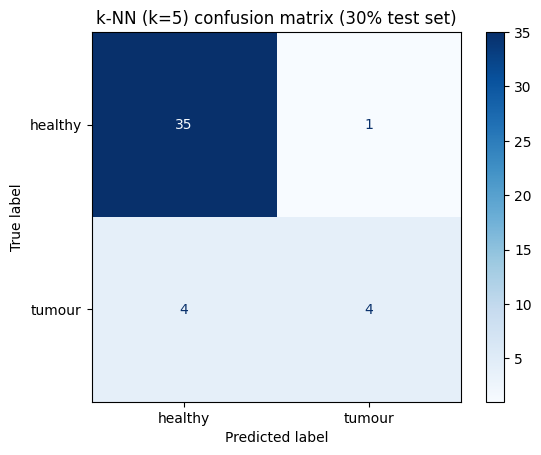

In [15]:
# confusion matrix of the test set (saved for the report)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(cm, display_labels=["healthy", "tumour"])
cm_display.plot(cmap="Blues")
plt.title(f"k-NN (k={best}) confusion matrix (30% test set)")
plt.savefig(FIGS + "/" + NAME + "_p3_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 7: Failed cases and the final model

The misclassified regions, then the model trained on all regions.

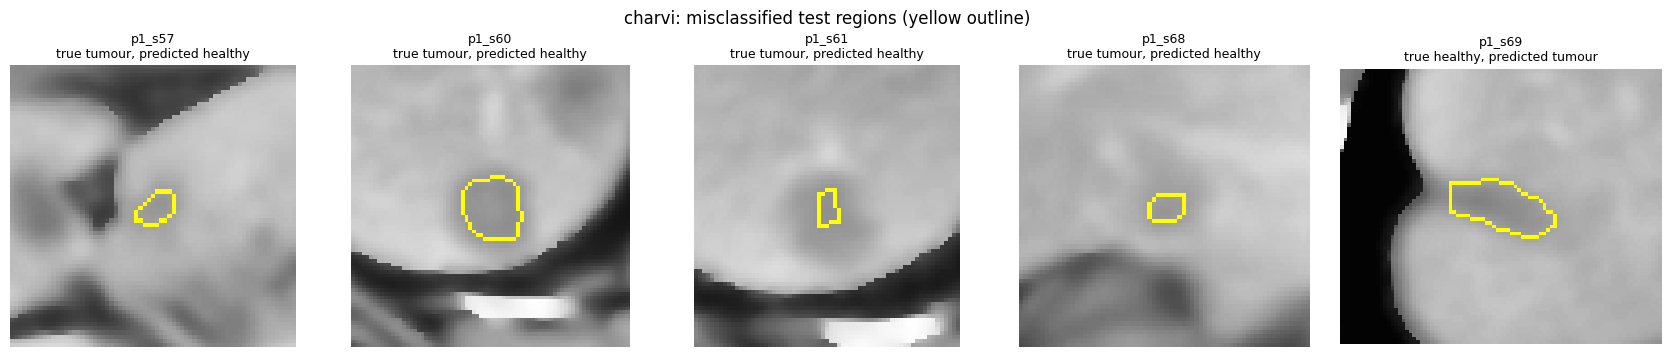

# Phase 3 failed cases: charvi

Test set: 44 regions, **5 misclassified**.

| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |
|---|---|---|---|---|---|
| p1_s57 | tumour | healthy | 65 | 90 | lbp_4 0.246 (z -1.6), glcm_homogeneity 0.864 (z +1.6), glcm_entropy 1.72 (z -1.6) |
| p1_s60 | tumour | healthy | 250 | 67 | lbp_0 0.008 (z +8000000.0), lbp_9 0.064 (z +38.4), lbp_1 0.02 (z +25.1) |
| p1_s61 | tumour | healthy | 50 | 68 | lbp_9 0.06 (z +35.9), glcm_homogeneity 1 (z +4.8), glcm_energy 1 (z +4.2) |
| p1_s68 | tumour | healthy | 56 | 76 | glcm_energy 0.698 (z +2.0), lbp_6 0.214 (z +2.0), glcm_entropy 1.37 (z -2.0) |
| p1_s69 | healthy | tumour | 338 | 74 | perimeter_area_ratio 0.232 (z -1.7), area 338 (z +1.1), glcm_energy 0.368 (z -0.9) |


In [16]:
# ---- failed cases: the test regions the classifier got wrong ----
FAILED = "../report/failed_cases/" + NAME
os.makedirs(FAILED, exist_ok=True)
wrong = idx_test[y_pred != y_test]
names = {0: "healthy", 1: "tumour"}

lines = []
lines.append(f"# Phase 3 failed cases: {NAME}")
lines.append("")
lines.append(f"Test set: {len(y_test)} regions, **{len(wrong)} misclassified**.")
lines.append("")
lines.append("| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |")
lines.append("|---|---|---|---|---|---|")

feat_cols = list(features.columns[2:])
train_feats = features.iloc[idx_train]
for i in wrong:
    sid, m, true_label = rois[i]
    row = features.iloc[i]
    # reason: the 3 features most unlike the training regions of its true class
    own_class = train_feats[train_feats.label == true_label][feat_cols]
    z = (row[feat_cols] - own_class.mean()) / (own_class.std() + 1e-9)
    z = z.astype(float)
    top = z.abs().sort_values(ascending=False).index[:3]
    why_parts = []
    for f in top:
        why_parts.append(f"{f} {row[f]:.3g} (z {z[f]:+.1f})")
    why = ", ".join(why_parts)
    lines.append(f"| {sid} | {names[true_label]} | {names[1 - true_label]} | {int(row['area'])} | {row['mean_HU']:.0f} | {why} |")

if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.4 * len(wrong), 3.6), squeeze=False)
    for j in range(len(wrong)):
        sid, m, true_label = rois[wrong[j]]
        ct, enhanced_img, liver_mask, tumour_mask = load(sid)
        rgb = cv2.cvtColor(enhanced_img, cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, (255, 255, 0), 1)
        # crop around the region with a 30 pixel border
        ys, xs = np.where(m)
        y0 = max(ys.min() - 30, 0)
        y1 = ys.max() + 30
        x0 = max(xs.min() - 30, 0)
        x1 = xs.max() + 30
        axes[0][j].imshow(rgb[y0:y1, x0:x1])
        axes[0][j].axis("off")
        axes[0][j].set_title(f"{sid}\ntrue {names[true_label]}, predicted {names[1 - true_label]}", fontsize=9)
    plt.suptitle(f"{NAME}: misclassified test regions (yellow outline)")
    plt.tight_layout()
    plt.savefig(FAILED + "/" + NAME + "_p3_misclassified.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    lines.append("| - | - | - | - | - | no mistakes in this test split |")

report_text = "\n".join(lines)
with open(FAILED + "/" + NAME + "_phase3_failed_cases.md", "w") as fh:
    fh.write(report_text)
print(report_text)

In [17]:
# final model trained on all regions, saved for the app
model.fit(X, y)
saved = {}
saved["model"] = model
saved["feature_names"] = list(features.columns[2:])
joblib.dump(saved, OUT + "/knn_model.joblib")
print("saved model to", OUT + "/knn_model.joblib")

saved model to outputs_charvi/knn_model.joblib


## Step 8: Feature analysis

Box plots, Mann-Whitney U tests and an ablation by feature group.

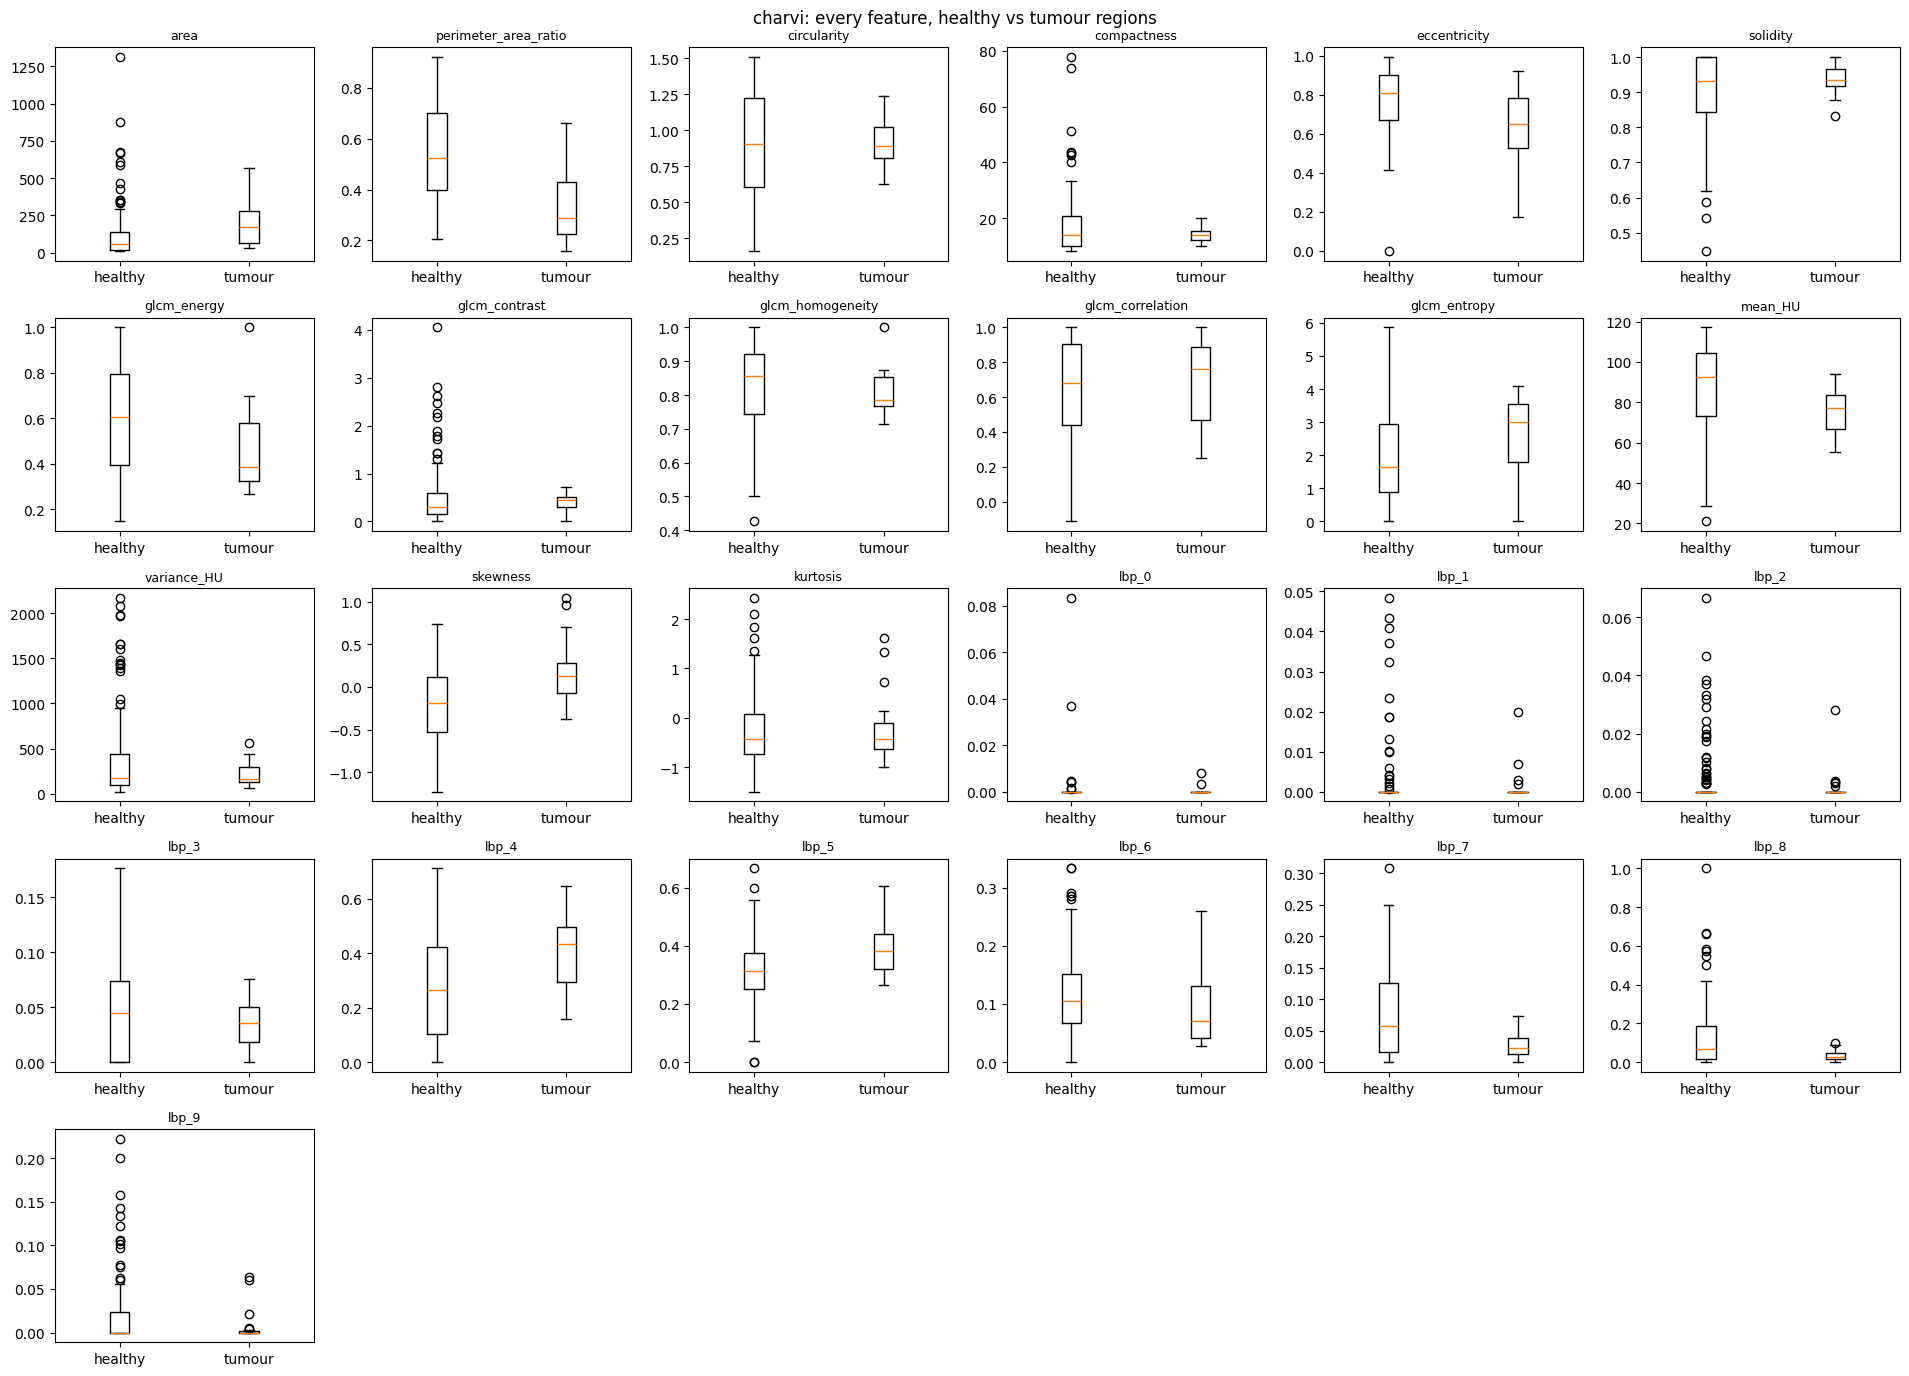

In [18]:
feature_names = list(features.columns[2:])
healthy = features[features.label == 0]
tumorous = features[features.label == 1]

# 1) box plots, healthy vs tumour
n_cols = 6
n_rows = int(np.ceil(len(feature_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows))
axes = axes.ravel()
for i in range(len(feature_names)):
    f = feature_names[i]
    axes[i].boxplot([healthy[f], tumorous[f]])
    axes[i].set_xticks([1, 2], ["healthy", "tumour"])
    axes[i].set_title(f, fontsize=9)
for i in range(len(feature_names), len(axes)):
    axes[i].axis("off")
plt.suptitle(f"{NAME}: every feature, healthy vs tumour regions")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p3_feature_boxplots.png", dpi=110)
plt.show()

In [19]:
# 2) Mann-Whitney U test per feature
test_rows = []
for f in feature_names:
    row = {}
    row["feature"] = f
    row["median healthy"] = healthy[f].median()
    row["median tumour"] = tumorous[f].median()
    row["p-value"] = mannwhitneyu(healthy[f], tumorous[f]).pvalue
    test_rows.append(row)
tests = pd.DataFrame(test_rows)
tests = tests.sort_values("p-value")
tests["significant (p < 0.05)"] = tests["p-value"] < 0.05
tests.to_csv(OUT + "/phase3_feature_tests.csv", index=False)
print("Mann-Whitney U, healthy vs tumour (smallest p first):")
print(tests.round(4).to_string(index=False))

Mann-Whitney U, healthy vs tumour (smallest p first):
             feature  median healthy  median tumour  p-value  significant (p < 0.05)
perimeter_area_ratio          0.5223         0.2892   0.0000                    True
                area         55.5000       175.0000   0.0002                    True
            skewness         -0.1844         0.1275   0.0005                    True
        eccentricity          0.8101         0.6501   0.0007                    True
               lbp_4          0.2649         0.4347   0.0008                    True
               lbp_7          0.0578         0.0222   0.0017                    True
               lbp_5          0.3122         0.3821   0.0020                    True
               lbp_8          0.0700         0.0259   0.0021                    True
             mean_HU         92.5779        77.3760   0.0023                    True
        glcm_entropy          1.6477         3.0051   0.0064                    True
         gl

In [20]:
# 3) ablation: one feature group at a time, same tuned classifier, same grouped split
SHAPE = ["area", "perimeter_area_ratio", "circularity", "compactness", "eccentricity", "solidity"]
FIRST_ORDER = ["mean_HU", "variance_HU", "skewness", "kurtosis"]
GLCM = []
LBP = []
for f in feature_names:
    if f.startswith("glcm_"):
        GLCM.append(f)
    if f.startswith("lbp_"):
        LBP.append(f)

feature_groups = {}
feature_groups["all features"] = feature_names
feature_groups["shape only"] = SHAPE
feature_groups["GLCM only"] = GLCM
feature_groups["first-order only"] = FIRST_ORDER
feature_groups["LBP only"] = LBP

ablation_rows = []
for group_name in feature_groups:
    cols_used = feature_groups[group_name]
    idx = []
    for c in cols_used:
        idx.append(feature_names.index(c))
    clf = clone(search.best_estimator_)
    cv_result = cross_validate(clf, X_train[:, idx], y_train, groups=groups[idx_train], cv=cv5, scoring="f1")
    cv_f1 = cv_result["test_score"]
    clf.fit(X_train[:, idx], y_train)
    pred = clf.predict(X_test[:, idx])
    row = {}
    row["features"] = group_name
    row["n"] = len(idx)
    row["CV F1 mean"] = cv_f1.mean()
    row["CV F1 std"] = cv_f1.std()
    row["test accuracy"] = accuracy_score(y_test, pred)
    row["test F1"] = f1_score(y_test, pred, zero_division=0)
    ablation_rows.append(row)

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(OUT + "/phase3_ablation.csv", index=False)
print("\nAblation (same tuned classifier, same grouped split):")
print(ablation.round(3).to_string(index=False))


Ablation (same tuned classifier, same grouped split):
        features  n  CV F1 mean  CV F1 std  test accuracy  test F1
    all features 25       0.743      0.143          0.886    0.615
      shape only  6       0.627      0.145          0.818    0.429
       GLCM only  5       0.630      0.119          0.818    0.333
first-order only  4       0.261      0.227          0.818    0.500
        LBP only 10       0.506      0.115          0.727    0.250
